# Task 3: Data Visualization & EDA
**Next Gen Software Hub Pvt. Ltd. | Data Science Internship 2026**
**Intern:** YOUR NAME HERE  |  **Domain:** Data Science  |  **Week 3**

---

## Goal
Explore the Titanic dataset visually with Matplotlib and Seaborn, handle missing values, and run a correlation analysis.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

df = sns.load_dataset("titanic")
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. Missing data: find it

In [2]:
missing = df.isnull().sum().sort_values(ascending=False)
pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": pct})[missing > 0]

,missing,percent
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


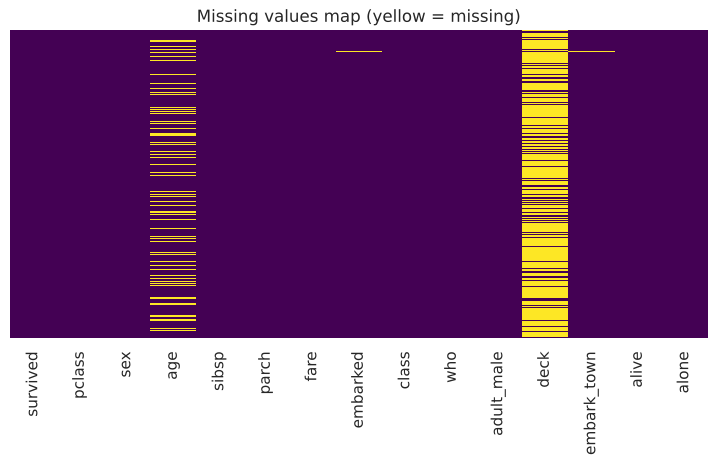

In [3]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values map (yellow = missing)")
plt.show()

## 2. Missing data: handle it
- `deck` is ~77% missing, so I drop it (too little information to impute).
- `age` (~20% missing) is filled with the **median age of the passenger's class and sex**, which is more accurate than one global value.
- `embarked` / `embark_town` have 2 missing values, filled with the mode.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop(columns=["deck"])

df_clean["age"] = df_clean.groupby(["pclass", "sex"])["age"].transform(lambda s: s.fillna(s.median()))

for col in ["embarked", "embark_town"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after cleaning:", df_clean.isnull().sum().sum())

Missing values after cleaning: 0


## 3. Bar charts

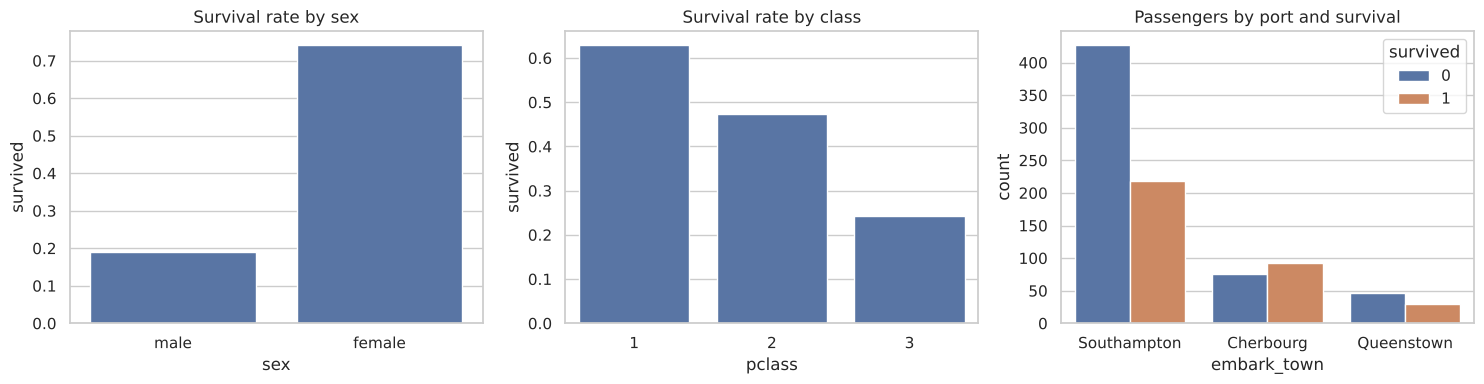

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=df_clean, x="sex", y="survived", ax=axes[0], errorbar=None)
axes[0].set_title("Survival rate by sex")

sns.barplot(data=df_clean, x="pclass", y="survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by class")

sns.countplot(data=df_clean, x="embark_town", hue="survived", ax=axes[2])
axes[2].set_title("Passengers by port and survival")

plt.tight_layout()
plt.show()

## 4. Histograms

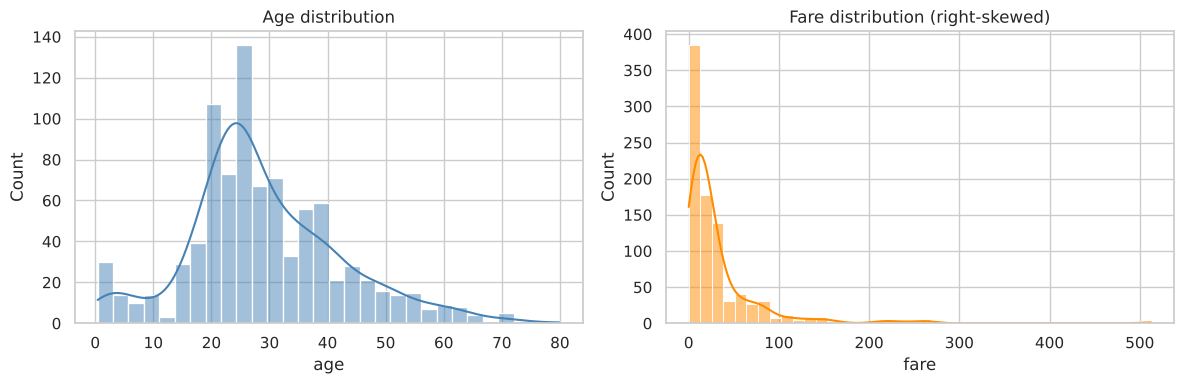

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["age"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Age distribution")

sns.histplot(df_clean["fare"], bins=40, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Fare distribution (right-skewed)")

plt.tight_layout()
plt.show()

## 5. Scatter plots

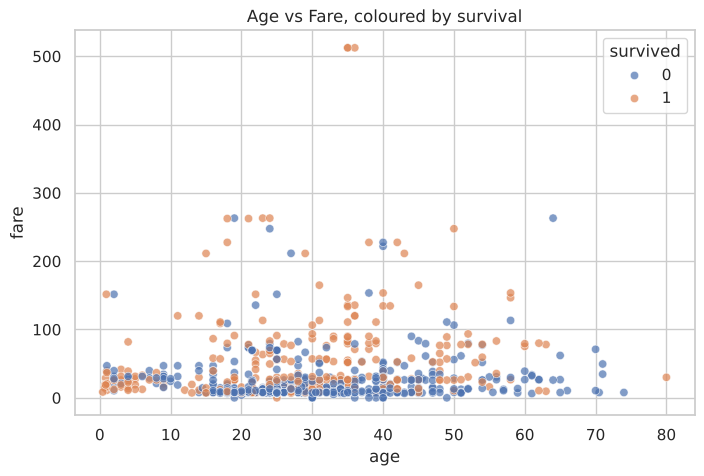

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="age", y="fare", hue="survived", alpha=0.7)
plt.title("Age vs Fare, coloured by survival")
plt.show()

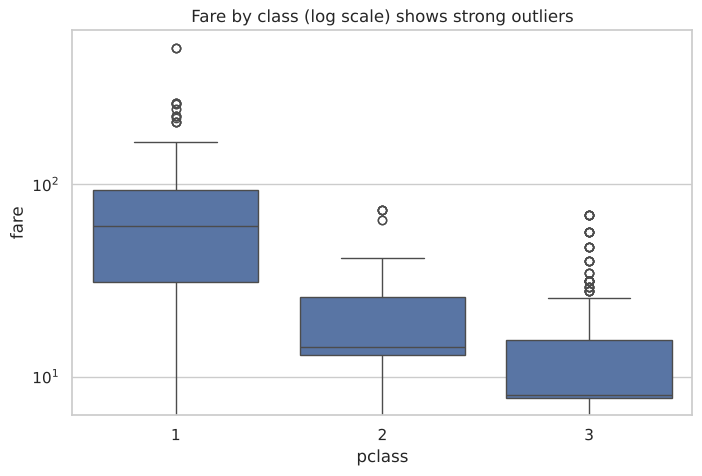

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="pclass", y="fare")
plt.yscale("log")
plt.title("Fare by class (log scale) shows strong outliers")
plt.show()

## 6. Correlation analysis

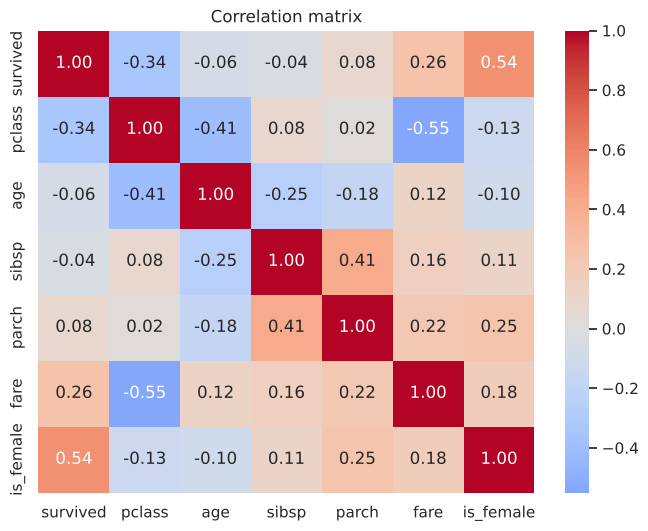

is_female    0.54
pclass      -0.34
fare         0.26
parch        0.08
age         -0.06
sibsp       -0.04
Name: survived, dtype: float64

In [9]:
num = df_clean[["survived", "pclass", "age", "sibsp", "parch", "fare"]].copy()
num["is_female"] = (df_clean["sex"] == "female").astype(int)

corr = num.corr().round(2)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix")
plt.show()

corr["survived"].drop("survived").sort_values(key=abs, ascending=False)

## 7. Key findings
1. **Sex** has the strongest relationship with survival (women much more likely to survive).
2. **Class** is the next strongest: higher class (lower `pclass` number) means better survival odds.
3. **Fare** is positively linked to survival, but mostly because it reflects class.
4. Age alone has only a weak correlation, although children had better survival chances.
5. Fare is heavily right-skewed with a few very large values. A log transform helps in modelling.

## Summary
Used bar charts, histograms, scatter, box plot and a heatmap, handled missing data with group-wise imputation, and ran correlation analysis.